In [41]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [47]:
df = pd.read_csv('./data/movie_blockbusters.csv')

## Data preparation and data cleaning

In [48]:
df.head()

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
0,1,Movie_0001,2020,2020s,Comedy,96,2.089233e+07,2.739209e+07,6.499763e+06,0.311,7.0,216326,9.64,0
1,2,Movie_0002,1981,1980s,Sci-Fi,128,3.063336e+08,1.237479e+09,9.311449e+08,3.040,5.3,49703,7.65,1
2,3,Movie_0003,1995,1990s,Horror,79,8.793950e+06,4.667246e+06,-4.126704e+06,-0.469,3.4,9476,16.68,0
3,4,Movie_0004,1988,1980s,Comedy,101,3.871710e+06,1.612737e+06,-2.258972e+06,-0.583,8.2,15698,2.93,0
4,5,Movie_0005,2023,2020s,Documentary,75,1.283539e+06,5.743469e+05,-7.091917e+05,-0.553,4.3,38698,9.10,0


In [49]:
df.describe()

,movie_id,year,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
count,5000.000000,5000.000000,5000.000000,5.000000e+03,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.00000
mean,2500.500000,2002.200600,109.358000,4.320764e+07,1.311844e+08,8.797676e+07,1.517586,5.997220,6.932152e+04,20.002864,0.13460
std,1443.520003,12.956324,22.217699,9.897210e+07,5.012581e+08,4.485541e+08,3.233827,1.494474,3.210306e+05,26.695885,0.34133
min,1.000000,1980.000000,60.000000,1.054897e+05,1.403244e+04,-8.009002e+08,-0.980000,1.000000,8.700000e+01,0.370000,0.00000
25%,1250.750000,1991.000000,93.000000,5.072756e+06,5.707047e+06,-1.252205e+06,-0.258000,5.000000,7.866750e+03,6.330000,0.00000
50%,2500.500000,2002.000000,109.000000,1.501351e+07,2.327998e+07,5.049109e+06,0.506500,6.000000,2.181550e+04,12.195000,0.00000
75%,3750.250000,2013.000000,126.000000,4.191808e+07,8.887134e+07,4.406719e+07,2.029000,7.000000,5.766675e+04,23.585000,0.00000
max,5000.000000,2024.000000,185.000000,2.369801e+09,1.495518e+10,1.455845e+10,43.322000,10.000000,1.823086e+07,627.870000,1.00000


In [50]:
df.isnull().sum()

movie_id       0
title          0
year           0
decade         0
genre          0
runtime_min    0
budget_usd     0
revenue_usd    0
profit_usd     0
roi            0
rating         0
vote_count     0
popularity     0
blockbuster    0
dtype: int64

In [51]:
df = df.drop_duplicates()

In [52]:
df.decade = df.decade.str.removesuffix('s').astype(int)

In [53]:
df.dtypes

movie_id         int64
title              str
year             int64
decade           int64
genre              str
runtime_min      int64
budget_usd     float64
revenue_usd    float64
profit_usd     float64
roi            float64
rating         float64
vote_count       int64
popularity     float64
blockbuster      int64
dtype: object

In [54]:
# Remove post-release metrics

del df['movie_id']
del df['title']
del df['revenue_usd']
del df['profit_usd']
del df['roi']
del df['rating']
del df['vote_count']
del df['popularity']

In [55]:
df.head()

,year,decade,genre,runtime_min,budget_usd,blockbuster
0,2020,2020,Comedy,96,2.089233e+07,0
1,1981,1980,Sci-Fi,128,3.063336e+08,1
2,1995,1990,Horror,79,8.793950e+06,0
3,1988,1980,Comedy,101,3.871710e+06,0
4,2023,2020,Documentary,75,1.283539e+06,0


## Dataset Partitioning

In [56]:
df_full_train, df_test = train_test_split(df, test_size=0.2, stratify=df.blockbuster)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, stratify=df_full_train.blockbuster)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.blockbuster.values
y_train = df_train.blockbuster.values
y_val = df_val.blockbuster.values
y_test = df_test.blockbuster.values

del df_full_train['blockbuster']
del df_train['blockbuster']
del df_val['blockbuster']
del df_test['blockbuster']

## EDA

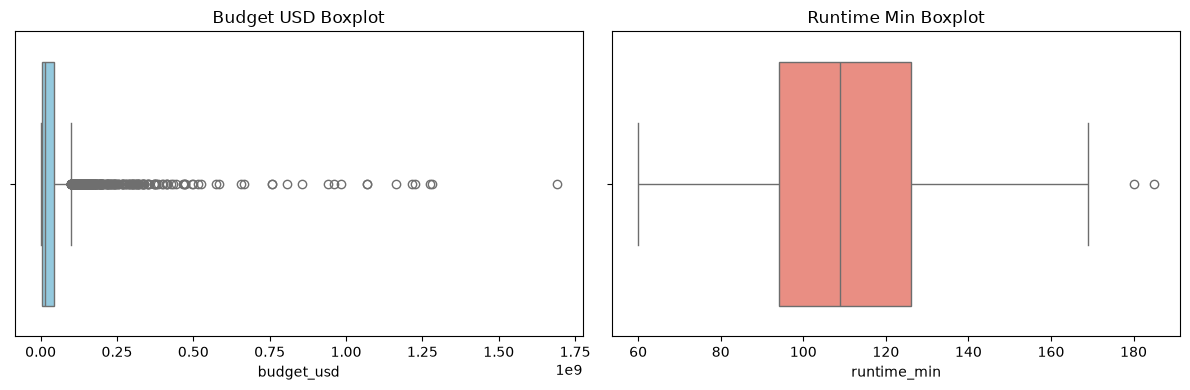

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_train['budget_usd'], ax=axes[0], color='skyblue').set_title('Budget USD Boxplot')
sns.boxplot(x=df_train['runtime_min'], ax=axes[1], color='salmon').set_title('Runtime Min Boxplot')
plt.tight_layout()

In [58]:
def prepare_features(df_input):
    df_out = df_input.copy()
    
    # 1. Log-transform skewed budget
    df_out['log_budget'] = np.log1p(df_out['budget_usd'])
    
    # 2. Financial intensity ratio (budget per minute)
    df_out['budget_per_min'] = df_out['budget_usd'] / df_out['runtime_min']
    
    return df_out

df_train_fe = prepare_features(df_train)
df_val_fe = prepare_features(df_val)

In [59]:
df_train_fe.head()

,year,decade,genre,runtime_min,budget_usd,log_budget,budget_per_min
0,2016,2010,Animation,97,2.266216e+07,16.936207,233630.557320
1,1992,1990,Animation,85,2.291187e+07,16.947166,269551.439529
2,2015,2010,Thriller,101,8.007651e+06,15.895908,79283.668812
3,2014,2010,Action,125,1.208205e+08,18.609817,966564.105200
4,2009,2000,Adventure,134,3.915682e+07,17.483085,292215.098507


In [60]:
# Categorical Encoding

train_dicts = df_train_fe.to_dict(orient='records')
val_dicts = df_val_fe.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [61]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [62]:
df.blockbuster.value_counts(normalize=True)

blockbuster
0    0.8654
1    0.1346
Name: proportion, dtype: float64